# Credit Risk Scoring — Machine Learning Workflow

**Project:** Consumer Loan Default Prediction  
**Dataset:** `cr_loan2.csv`  
**Target:** `loan_status` (0 = Non-Default, 1 = Default)  
**Primary Model:** Logistic Regression  

---

This notebook follows a professional **Finance Data Science** workflow:

1. **Part 1** — Data Exploration & Preparation  
2. **Part 2** — Model Building & Evaluation  
3. **Part 3** — Operationalization & Business Impact  

> *Interpretation note:* In credit risk, **default (1)** is the event of interest. Model performance should balance **recall on defaults** (catching bad loans) with **precision** (avoiding unnecessary rejections of good borrowers).


---
# Part 1 — Data Exploration and Preparation


## 1. Import Required Libraries


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

# Finance Data Science visual style
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
DATA_PATH = "cr_loan2.csv"


Matplotlib is building the font cache; this may take a moment.


## 2. Load the Dataset


In [ ]:
df = pd.read_csv(DATA_PATH)
df_raw = df.copy()  # preserve original for audit trail

print("Dataset loaded successfully.")
print(f"File: {DATA_PATH}")


Dataset loaded successfully.
File: cr_loan2.csv


## 3. Initial Data Inspection


In [ ]:
print("=" * 60)
print("FIRST ROWS")
display(df.head(10))

print("\nSHAPE:", df.shape)
print("\nCOLUMNS:", list(df.columns))
print("\nDATA TYPES:")
print(df.dtypes)

print("\nDESCRIPTIVE STATISTICS (numerical):")
display(df.describe().T)

print("\nDESCRIPTIVE STATISTICS (categorical):")
display(df.describe(include="object").T)


FIRST ROWS


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0000,PERSONAL,D,35000,16.0200,1,0.5900,Y,3
1,21,9600,OWN,5.0000,EDUCATION,B,1000,11.1400,0,0.1000,N,2
2,25,9600,MORTGAGE,1.0000,MEDICAL,C,5500,12.8700,1,0.5700,N,3
3,23,65500,RENT,4.0000,MEDICAL,C,35000,15.2300,1,0.5300,N,2
4,24,54400,RENT,8.0000,MEDICAL,C,35000,14.2700,1,0.5500,Y,4
5,21,9900,OWN,2.0000,VENTURE,A,2500,7.1400,1,0.2500,N,2
6,26,77100,RENT,8.0000,EDUCATION,B,35000,12.4200,1,0.4500,N,3
7,24,78956,RENT,5.0000,MEDICAL,B,35000,11.1100,1,0.4400,N,4
8,24,83000,RENT,8.0000,PERSONAL,A,35000,8.9000,1,0.4200,N,2
9,21,10000,OWN,6.0000,VENTURE,D,1600,14.7400,1,0.1600,N,3



SHAPE: (32581, 12)

COLUMNS: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

DATA TYPES:
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

DESCRIPTIVE STATISTICS (numerical):


,count,mean,std,min,25%,50%,75%,max
person_age,"32,581.0000",27.7346,6.3481,20.0000,23.0000,26.0000,30.0000,144.0000
person_income,"32,581.0000","66,074.8485","61,983.1192","4,000.0000","38,500.0000","55,000.0000","79,200.0000","6,000,000.0000"
person_emp_length,"31,686.0000",4.7897,4.1426,0.0000,2.0000,4.0000,7.0000,123.0000
loan_amnt,"32,581.0000","9,589.3711","6,322.0866",500.0000,"5,000.0000","8,000.0000","12,200.0000","35,000.0000"
loan_int_rate,"29,465.0000",11.0117,3.2405,5.4200,7.9000,10.9900,13.4700,23.2200
loan_status,"32,581.0000",0.2182,0.4130,0.0000,0.0000,0.0000,0.0000,1.0000
loan_percent_income,"32,581.0000",0.1702,0.1068,0.0000,0.0900,0.1500,0.2300,0.8300
cb_person_cred_hist_length,"32,581.0000",5.8042,4.0550,2.0000,3.0000,4.0000,8.0000,30.0000



DESCRIPTIVE STATISTICS (categorical):


,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


## 4. Data Description


### 4.1 Variable Overview

| Variable | Type | Business Meaning |
|----------|------|------------------|
| `person_age` | Numerical | Applicant age |
| `person_income` | Numerical | Annual income |
| `person_home_ownership` | Categorical | Housing status (RENT/OWN/MORTGAGE/OTHER) |
| `person_emp_length` | Numerical | Employment tenure (years) |
| `loan_intent` | Categorical | Stated purpose of the loan |
| `loan_grade` | Categorical | Internal risk grade assigned to the loan |
| `loan_amnt` | Numerical | Loan principal amount |
| `loan_int_rate` | Numerical | Interest rate (%) |
| `loan_status` | **Target** | 0 = repaid, 1 = default |
| `loan_percent_income` | Numerical | Loan amount as share of income |
| `cb_person_default_on_file` | Categorical | Prior default flag (Y/N) |
| `cb_person_cred_hist_length` | Numerical | Credit history length (years) |


### 4.2 Numerical, Categorical, and Target Analysis


In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical variables:", num_cols)
print("Categorical variables:", cat_cols)

print("\n--- Missing values ---")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
display(missing_df[missing_df["missing_count"] > 0])

print("\n--- Target variable: loan_status ---")
target_counts = df["loan_status"].value_counts().sort_index()
target_pct = df["loan_status"].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_pct.round(2)
})
target_summary.index = target_summary.index.map({0: "Non-Default (0)", 1: "Default (1)"})
display(target_summary)

print("\n--- Categorical cardinality ---")
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(5), "\n")


Numerical variables: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical variables: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

--- Missing values ---


,missing_count,missing_pct
person_emp_length,895,2.7500
loan_int_rate,3116,9.5600



--- Target variable: loan_status ---


,count,percentage
loan_status,,
Non-Default (0),25473,78.1800
Default (1),7108,21.8200



--- Categorical cardinality ---
person_home_ownership: 4 unique values
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64 



loan_intent: 6 unique values
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
Name: count, dtype: int64 

loan_grade: 7 unique values
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
Name: count, dtype: int64 

cb_person_default_on_file: 2 unique values
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64 



## 5. Exploratory Data Analysis (EDA)


### 5.1 Target Variable Distribution


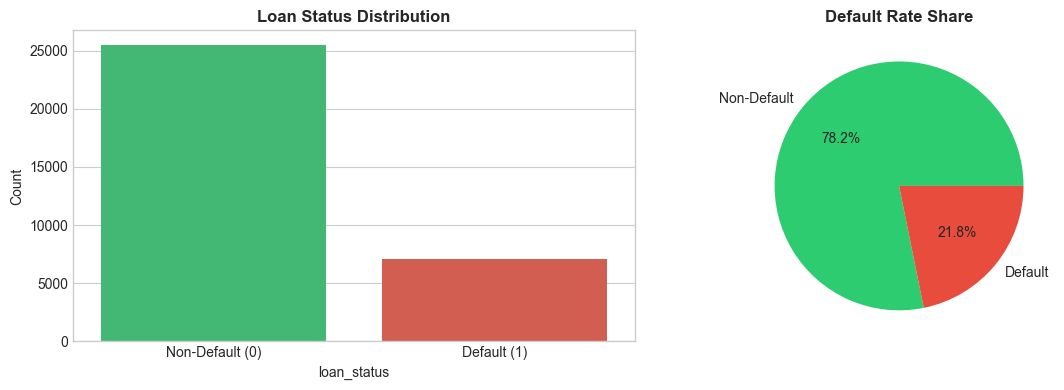

Portfolio default rate: 21.82%
Class imbalance present — stratified sampling and balanced metrics recommended.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="loan_status", ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Loan Status Distribution", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(["Non-Default (0)", "Default (1)"])
axes[0].set_ylabel("Count")

df["loan_status"].value_counts(normalize=True).plot(
    kind="pie", ax=axes[1], autopct="%1.1f%%",
    colors=["#2ecc71", "#e74c3c"], labels=["Non-Default", "Default"]
)
axes[1].set_title("Default Rate Share", fontsize=12, fontweight="bold")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

default_rate = df["loan_status"].mean()
print(f"Portfolio default rate: {default_rate:.2%}")
print("Class imbalance present — stratified sampling and balanced metrics recommended.")


### 5.2 Histograms — Key Numerical Variables


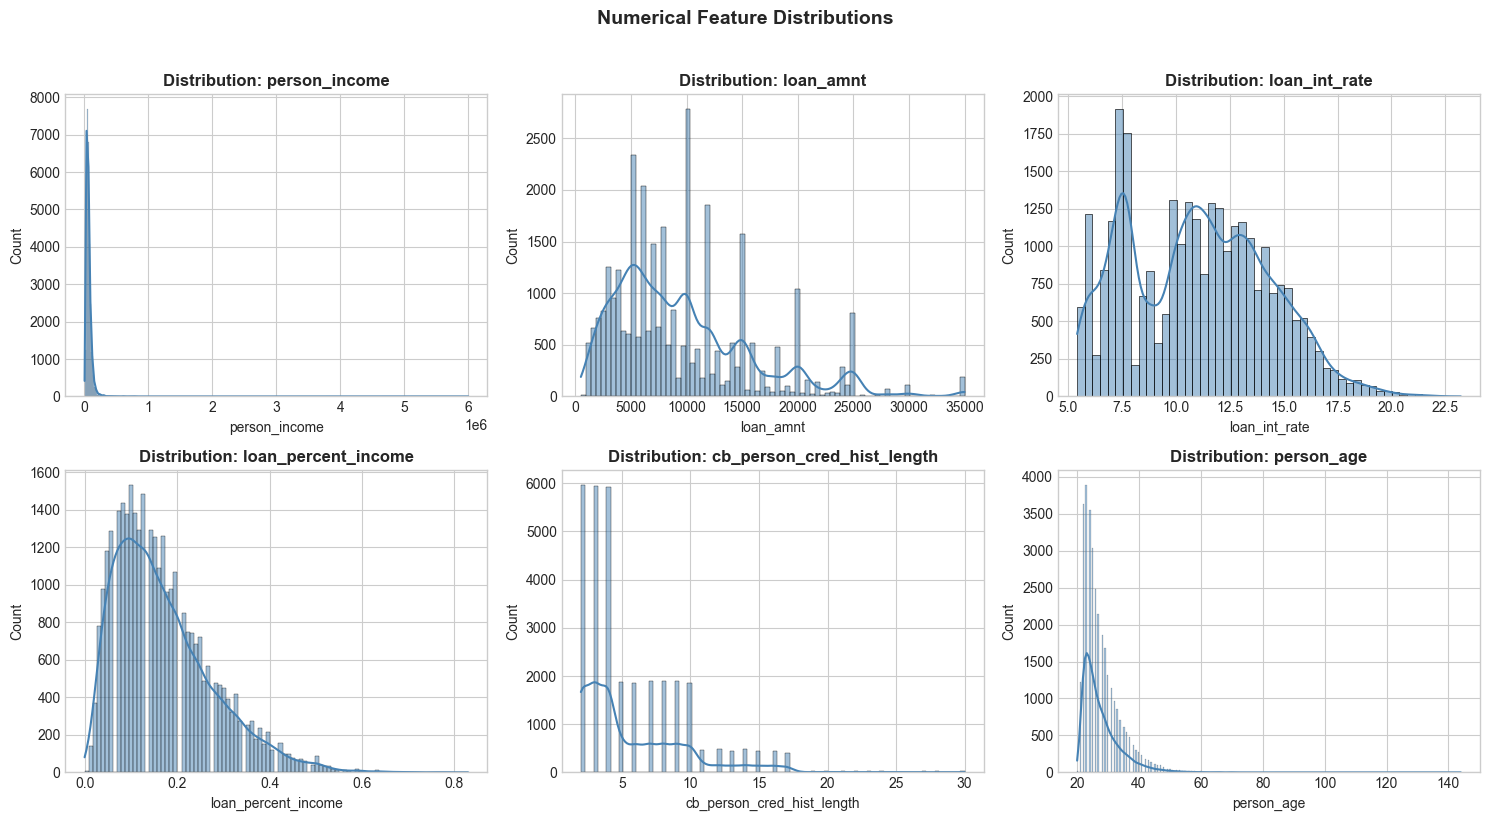

In [ ]:
key_numeric = [
    "person_income", "loan_amnt", "loan_int_rate",
    "loan_percent_income", "cb_person_cred_hist_length", "person_age"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(key_numeric):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution: {col}", fontweight="bold")

plt.suptitle("Numerical Feature Distributions", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 5.3 Boxplots — Outlier Visualization


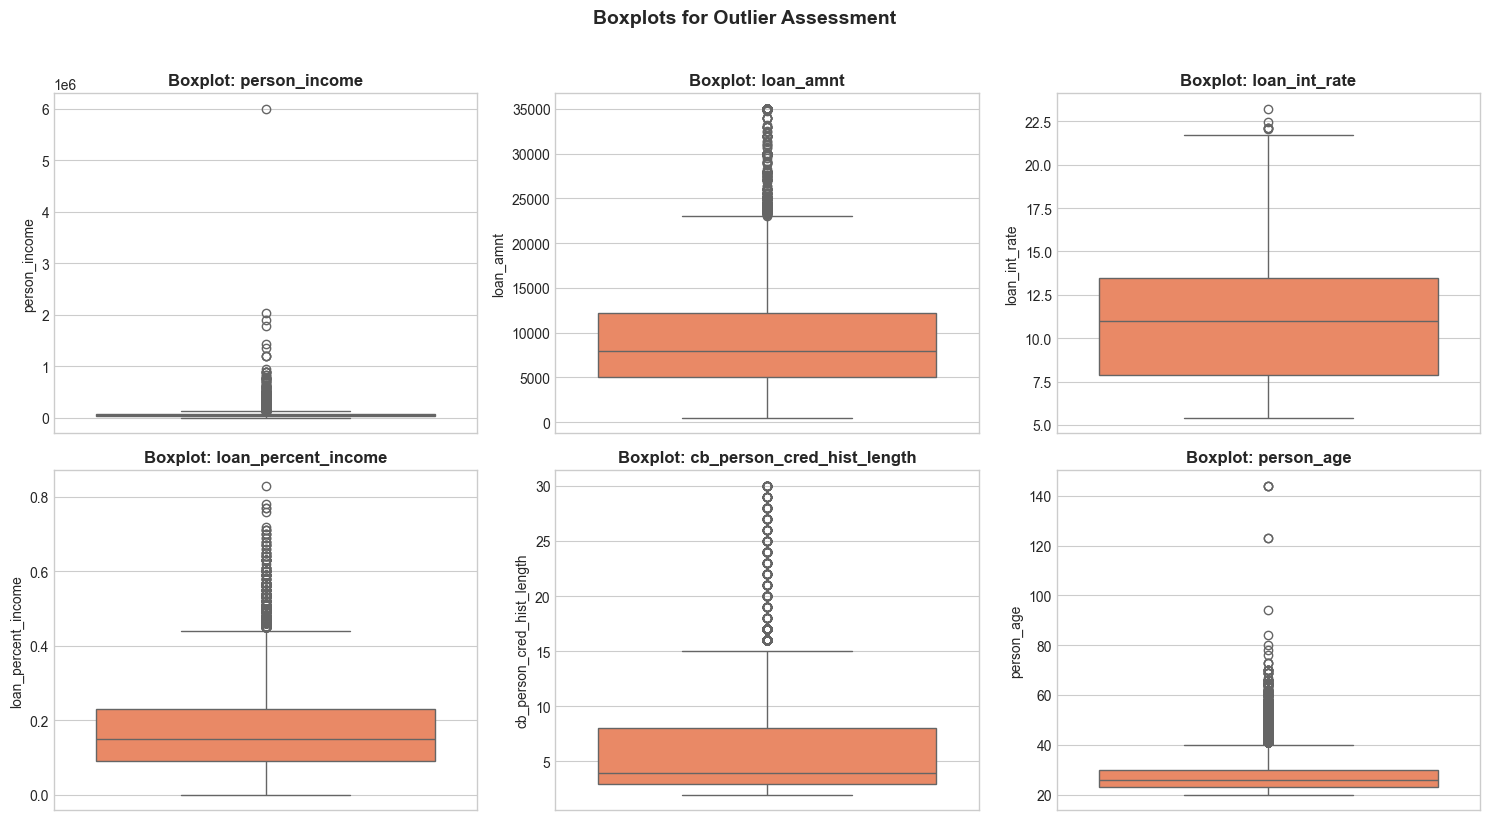

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(key_numeric):
    sns.boxplot(y=df[col], ax=axes[i], color="coral")
    axes[i].set_title(f"Boxplot: {col}", fontweight="bold")

plt.suptitle("Boxplots for Outlier Assessment", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 5.4 Countplots — Categorical Variables


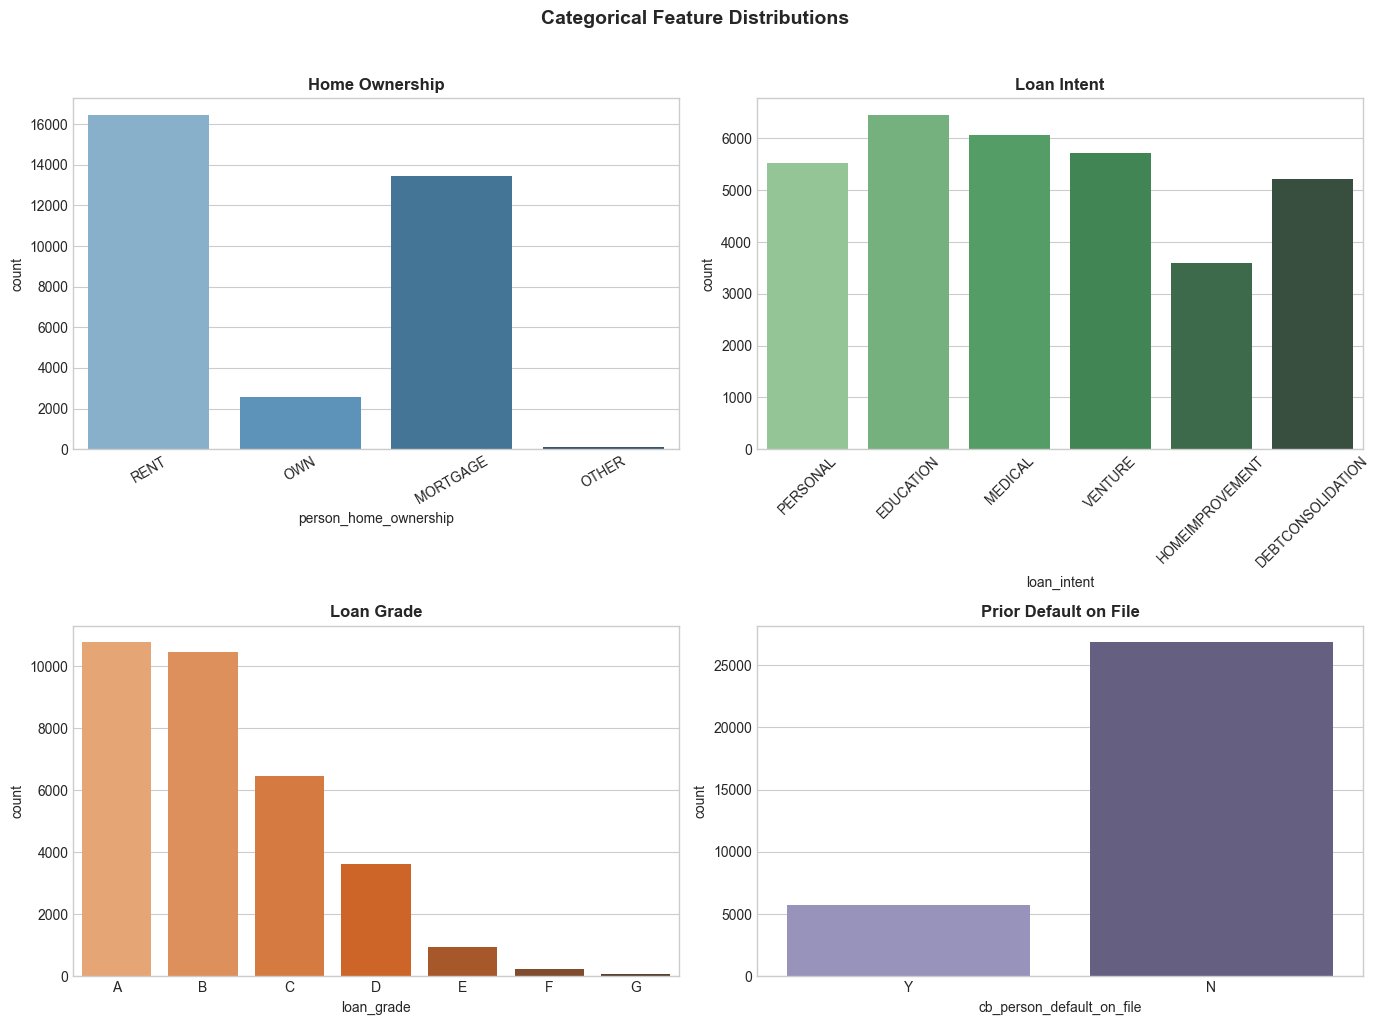

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x="person_home_ownership", ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("Home Ownership", fontweight="bold")
axes[0, 0].tick_params(axis="x", rotation=30)

sns.countplot(data=df, x="loan_intent", ax=axes[0, 1], palette="Greens_d")
axes[0, 1].set_title("Loan Intent", fontweight="bold")
axes[0, 1].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="loan_grade", ax=axes[1, 0], palette="Oranges_d", order=sorted(df["loan_grade"].unique()))
axes[1, 0].set_title("Loan Grade", fontweight="bold")

sns.countplot(data=df, x="cb_person_default_on_file", ax=axes[1, 1], palette="Purples_d")
axes[1, 1].set_title("Prior Default on File", fontweight="bold")

plt.suptitle("Categorical Feature Distributions", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 5.5 Correlation Heatmap


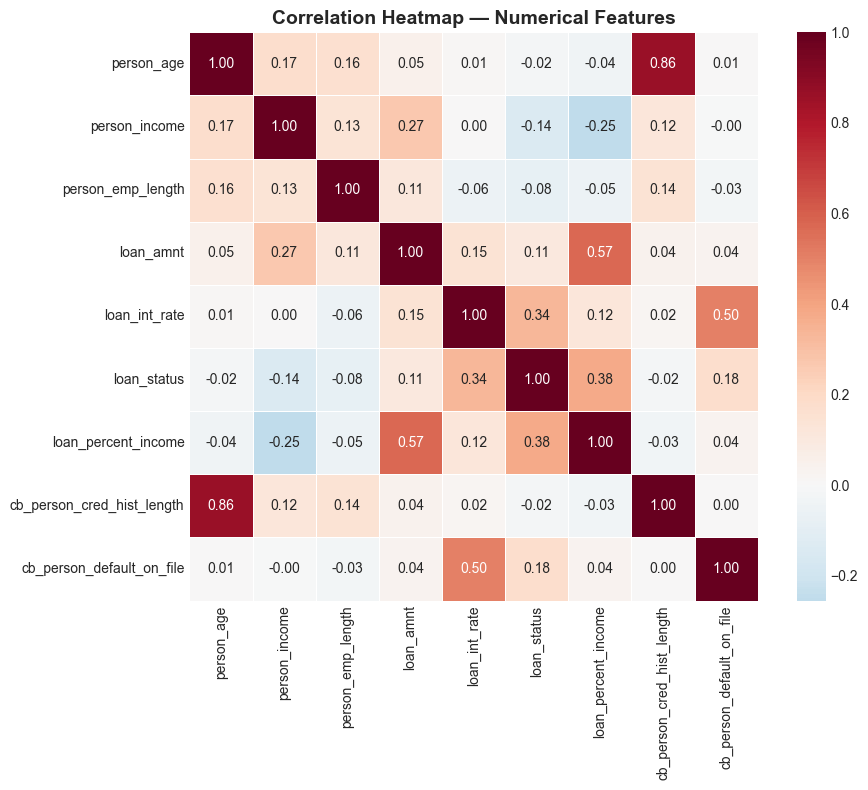

In [ ]:
# Encode binary categorical for correlation matrix
df_corr = df.copy()
df_corr["cb_person_default_on_file"] = df_corr["cb_person_default_on_file"].map({"N": 0, "Y": 1})

corr_matrix = df_corr[num_cols + ["cb_person_default_on_file"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    square=True, linewidths=0.5
)
plt.title("Correlation Heatmap — Numerical Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 5.6 Pair Relationships (Key Risk Drivers)


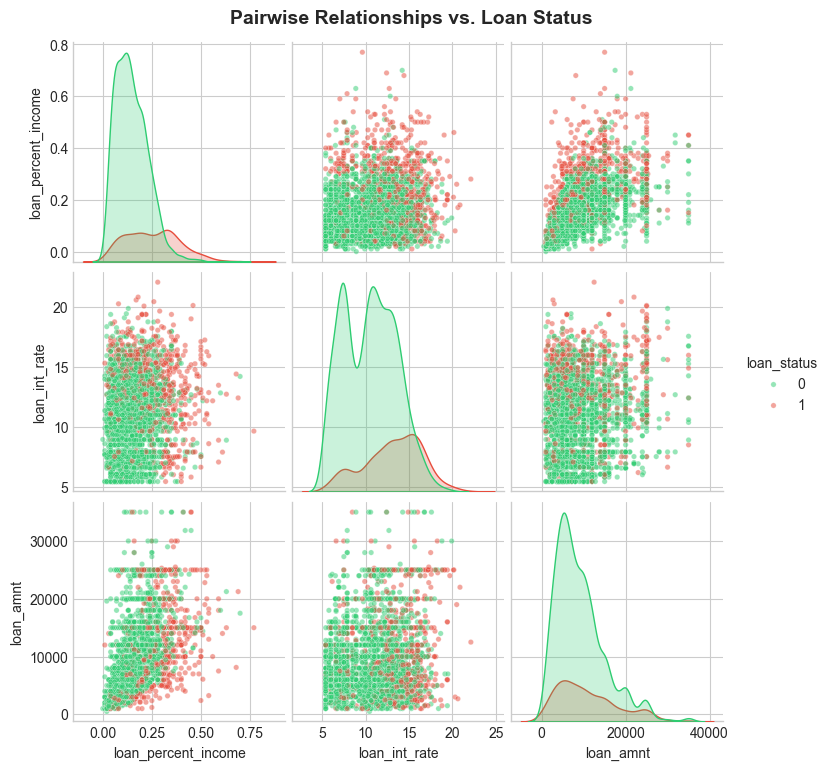

In [ ]:
pair_cols = ["loan_percent_income", "loan_int_rate", "loan_amnt", "loan_status"]
sample_df = df[pair_cols].dropna().sample(n=min(3000, len(df)), random_state=RANDOM_STATE)

g = sns.pairplot(
    sample_df, hue="loan_status", palette={0: "#2ecc71", 1: "#e74c3c"},
    diag_kind="kde", corner=False, plot_kws={"alpha": 0.5, "s": 15}
)
g.fig.suptitle("Pairwise Relationships vs. Loan Status", y=1.02, fontsize=14, fontweight="bold")
plt.show()


### 5.7 Default vs. Non-Default Comparative Analysis


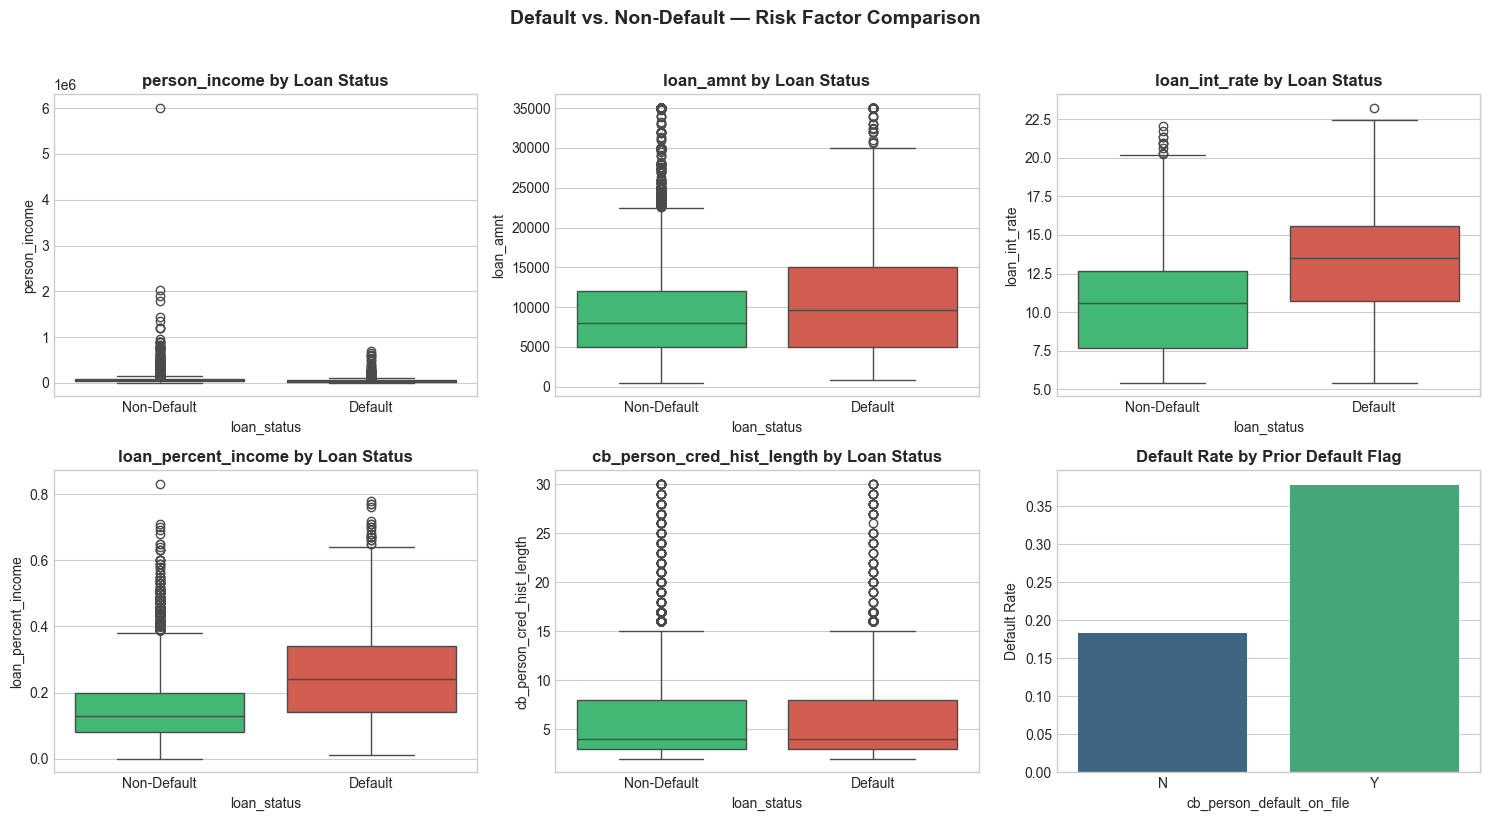

Mean values by loan status:


,Non-Default,Default
person_income,"70,804.3600","49,125.6500"
loan_amnt,"9,237.4600","10,850.5000"
loan_int_rate,10.4400,13.0600
loan_percent_income,0.1500,0.2500
cb_person_cred_hist_length,5.8400,5.6900


In [ ]:
compare_vars = [
    "person_income", "loan_amnt", "loan_int_rate",
    "loan_percent_income", "cb_person_cred_hist_length"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(compare_vars):
    sns.boxplot(data=df, x="loan_status", y=col, ax=axes[i], palette=["#2ecc71", "#e74c3c"])
    axes[i].set_title(f"{col} by Loan Status", fontweight="bold")
    axes[i].set_xticklabels(["Non-Default", "Default"])

# Default rate by categorical risk factors
sns.barplot(
    data=df.groupby("cb_person_default_on_file")["loan_status"].mean().reset_index(),
    x="cb_person_default_on_file", y="loan_status", ax=axes[-1], palette="viridis"
)
axes[-1].set_title("Default Rate by Prior Default Flag", fontweight="bold")
axes[-1].set_ylabel("Default Rate")

plt.suptitle("Default vs. Non-Default — Risk Factor Comparison", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Summary table: mean values by status
summary_by_status = df.groupby("loan_status")[compare_vars].mean().T
summary_by_status.columns = ["Non-Default", "Default"]
print("Mean values by loan status:")
display(summary_by_status.round(2))


## 6. Outlier Detection and Treatment


We apply the **Interquartile Range (IQR)** method:

- Lower bound = Q1 − 1.5 × IQR  
- Upper bound = Q3 + 1.5 × IQR  

Extreme values are **winsorized** (capped) rather than deleted to retain sample size — standard practice in retail credit portfolios.


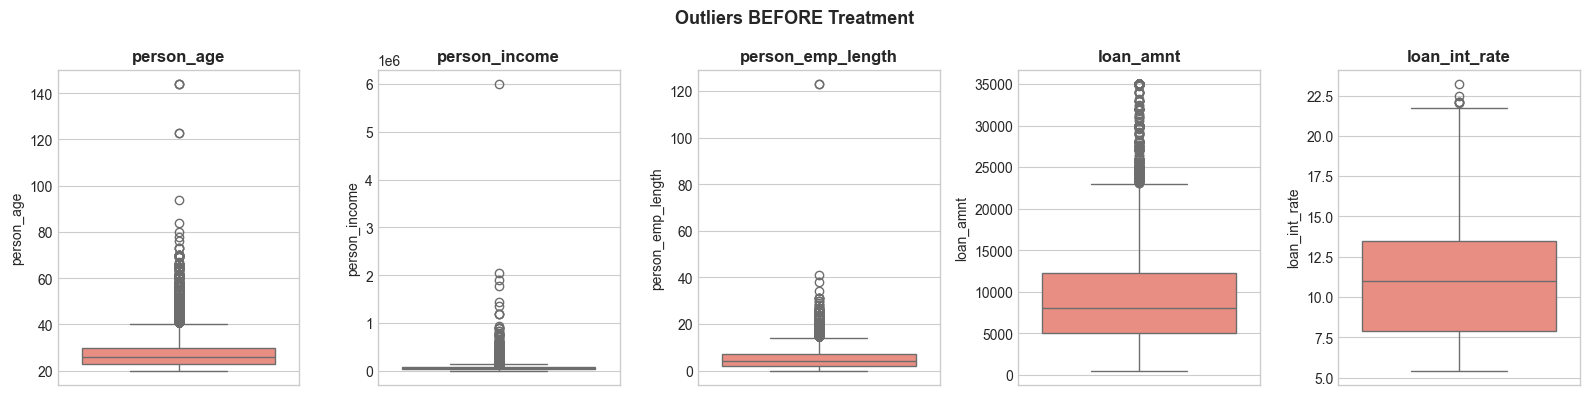

Outlier capping summary:


,variable,capped_low,capped_high,lower_bound,upper_bound
0,person_age,0,1494,12.5000,40.5000
1,person_income,0,1484,"-22,550.0000","140,250.0000"
2,person_emp_length,0,853,-5.5000,14.5000
3,loan_amnt,0,1689,"-5,800.0000","23,000.0000"
4,loan_int_rate,0,6,-0.4550,21.8250


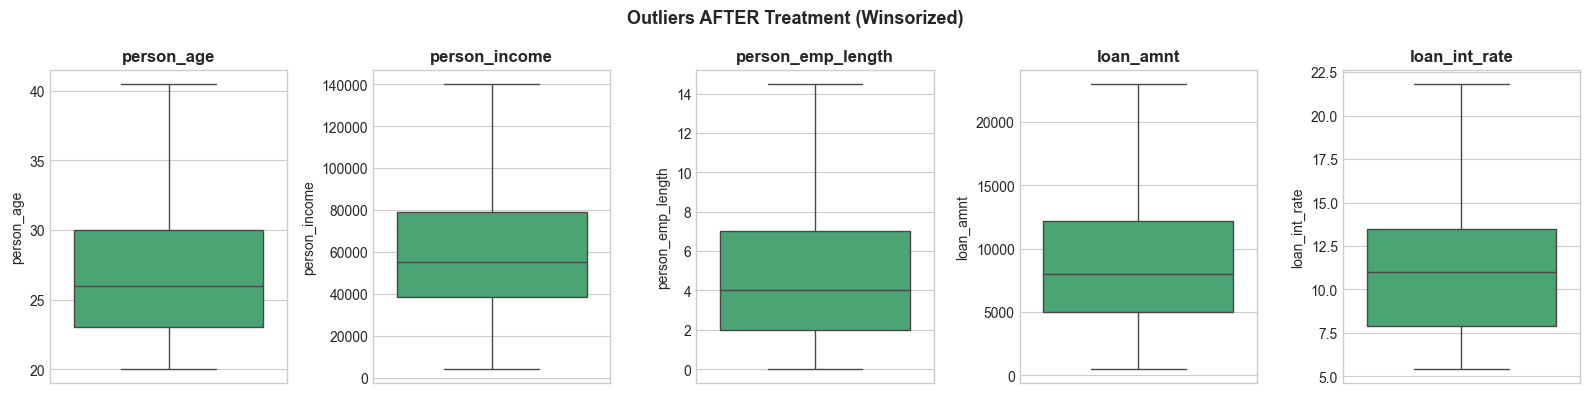

Impact: Extreme ages (e.g., 144 years) and implausible employment lengths are capped,
reducing leverage from data errors while preserving borrower records.


In [ ]:
def iqr_bounds(series, factor=1.5):
    """Compute IQR lower/upper bounds for a numeric series."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - factor * iqr, q3 + factor * iqr


def cap_outliers(df_in, columns, factor=1.5):
    """Winsorize extreme values to IQR bounds."""
    df_out = df_in.copy()
    report = []
    for col in columns:
        low, high = iqr_bounds(df_out[col].dropna(), factor=factor)
        n_low = (df_out[col] < low).sum()
        n_high = (df_out[col] > high).sum()
        df_out[col] = df_out[col].clip(lower=low, upper=high)
        report.append({"variable": col, "capped_low": n_low, "capped_high": n_high, "lower_bound": low, "upper_bound": high})
    return df_out, pd.DataFrame(report)


outlier_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate"]

# Visualize before treatment
fig, axes = plt.subplots(1, len(outlier_cols), figsize=(16, 4))
for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df[col].dropna(), ax=axes[i], color="salmon")
    axes[i].set_title(col, fontweight="bold")
plt.suptitle("Outliers BEFORE Treatment", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

df, outlier_report = cap_outliers(df, outlier_cols)
print("Outlier capping summary:")
display(outlier_report)

fig, axes = plt.subplots(1, len(outlier_cols), figsize=(16, 4))
for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df[col].dropna(), ax=axes[i], color="mediumseagreen")
    axes[i].set_title(col, fontweight="bold")
plt.suptitle("Outliers AFTER Treatment (Winsorized)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Impact: Extreme ages (e.g., 144 years) and implausible employment lengths are capped,")
print("reducing leverage from data errors while preserving borrower records.")


## 7. Data Processing


### 7.1 Missing Values and Duplicates


In [ ]:
# Missing value treatment
# Employment length: median imputation (stable, robust to skew)
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())

# Interest rate: median within loan grade (preserves risk pricing structure)
df["loan_int_rate"] = df.groupby("loan_grade")["loan_int_rate"].transform(
    lambda x: x.fillna(x.median())
)
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())

print("Missing values after imputation:")
print(df.isnull().sum().sum(), "total missing cells")

# Remove duplicate applications
n_before = len(df)
df = df.drop_duplicates()
print(f"Duplicates removed: {n_before - len(df)} rows")
print(f"Final shape: {df.shape}")


Missing values after imputation:
0 total missing cells
Duplicates removed: 165 rows
Final shape: (32416, 12)


### 7.2 Feature Engineering


In [ ]:
# --- Financial risk features ---
df["prior_default_flag"] = (df["cb_person_default_on_file"] == "Y").astype(int)
df["short_credit_history"] = (df["cb_person_cred_hist_length"] < 3).astype(int)
df["high_payment_burden"] = (df["loan_percent_income"] > 0.40).astype(int)
df["income_to_loan_ratio"] = df["person_income"] / df["loan_amnt"].replace(0, np.nan)
df["annual_interest_cost"] = df["loan_amnt"] * (df["loan_int_rate"] / 100)

# Income risk tiers (portfolio segmentation feature)
df["income_tier"] = pd.qcut(
    df["person_income"], q=5, labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

# Age groups
df["age_group"] = pd.cut(
    df["person_age"], bins=[0, 25, 35, 50, 100], labels=["Young", "Adult", "Middle", "Senior"]
)

print("Engineered features created:")
engineered = [
    "prior_default_flag", "short_credit_history", "high_payment_burden",
    "income_to_loan_ratio", "annual_interest_cost", "income_tier", "age_group"
]
display(df[engineered].head())


Engineered features created:


,prior_default_flag,short_credit_history,high_payment_burden,income_to_loan_ratio,annual_interest_cost,income_tier,age_group
0,1,0,1,2.5652,"3,684.6000",Medium,Young
1,0,1,0,9.6000,111.4000,Very Low,Young
2,0,0,1,1.7455,707.8500,Very Low,Young
3,0,1,1,2.8478,"3,502.9000",High,Young
4,1,0,1,2.3652,"3,282.1000",Medium,Young


### 7.3 Categorical Encoding, Scaling, and Train-Test Split


In [ ]:
# Target and feature separation
y = df["loan_status"]
X = df.drop(columns=["loan_status"])

# One-hot encoding for categorical variables
X_encoded = pd.get_dummies(X, drop_first=True)

# Train-test split (stratified to preserve default rate)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# StandardScaler — fit on training data only (prevents leakage)
scaler = StandardScaler()
scale_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print(f"Training set: {X_train_scaled.shape[0]:,} observations, {X_train_scaled.shape[1]} features")
print(f"Test set:     {X_test_scaled.shape[0]:,} observations")
print(f"Train default rate: {y_train.mean():.2%}")
print(f"Test default rate:  {y_test.mean():.2%}")


Training set: 25,932 observations, 34 features
Test set:     6,484 observations
Train default rate: 21.87%
Test default rate:  21.87%


### 7.4 Feature Importance (Logistic Regression — Post-Training Preview)


*Feature importance coefficients are computed after model training in Part 2 (Section 2.4).*


---
# Part 2 — Model Building (Logistic Regression)


## 1. Train Logistic Regression


We use **Logistic Regression** with `class_weight='balanced'` to address class imbalance.

Logistic regression is widely used in credit scoring because it is:
- Interpretable (coefficients map to log-odds of default)
- Regulator-friendly
- Fast to deploy in production


In [ ]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    solver="lbfgs"
)

log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]  # P(default)

print("Model trained successfully.")
print(f"Intercept: {log_reg.intercept_[0]:.4f}")


Model trained successfully.
Intercept: -0.4713


## 2. Model Evaluation


In [ ]:
# Classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Value": [accuracy, precision, recall, f1, roc_auc]
})
display(metrics_df.round(4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Non-Default", "Default"]))


,Metric,Value
0,Accuracy,0.8138
1,Precision,0.5526
2,Recall,0.7814
3,F1-Score,0.6474
4,ROC-AUC,0.8733



Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.93      0.82      0.87      5066
     Default       0.55      0.78      0.65      1418

    accuracy                           0.81      6484
   macro avg       0.74      0.80      0.76      6484
weighted avg       0.85      0.81      0.82      6484



## 3. Confusion Matrix and ROC Curve


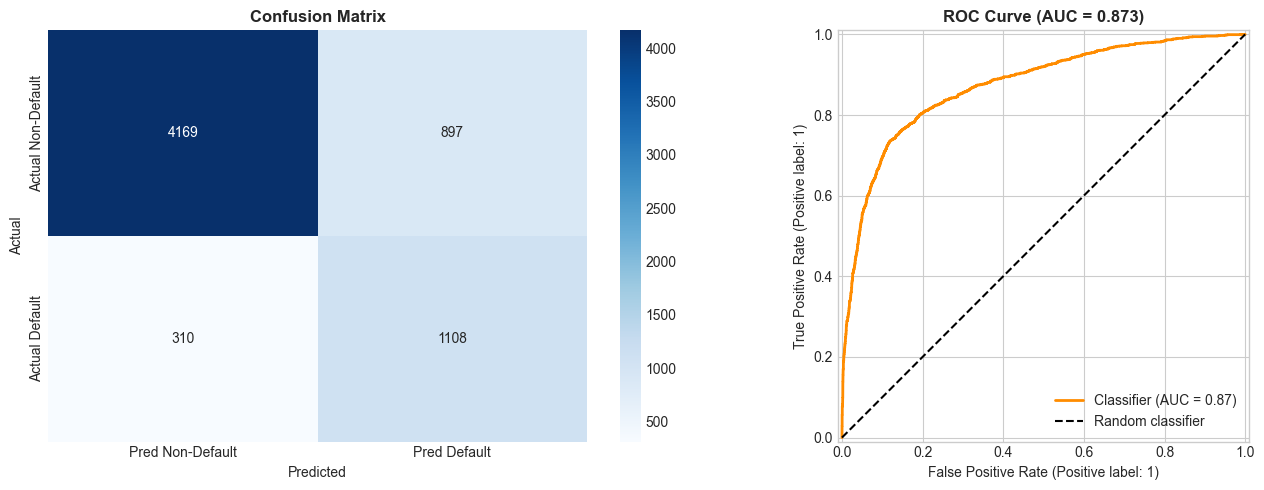

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
    xticklabels=["Pred Non-Default", "Pred Default"],
    yticklabels=["Actual Non-Default", "Actual Default"]
)
axes[0].set_title("Confusion Matrix", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], color="darkorange", lw=2)
axes[1].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[1].set_title(f"ROC Curve (AUC = {roc_auc:.3f})", fontsize=12, fontweight="bold")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 4. Coefficients and Interpretation


Top 15 drivers of default risk (by |coefficient|):


,feature,coefficient,abs_coefficient
25,loan_grade_G,3.3742,3.3742
24,loan_grade_F,2.5661,2.5661
23,loan_grade_E,2.2754,2.2754
22,loan_grade_D,2.1448,2.1448
13,person_home_ownership_OWN,-1.7472,1.7472
5,loan_percent_income,1.2043,1.2043
19,loan_intent_VENTURE,-1.0397,1.0397
27,income_tier_Low,-0.6250,0.6250
28,income_tier_Medium,-0.6234,0.6234
15,loan_intent_EDUCATION,-0.6131,0.6131


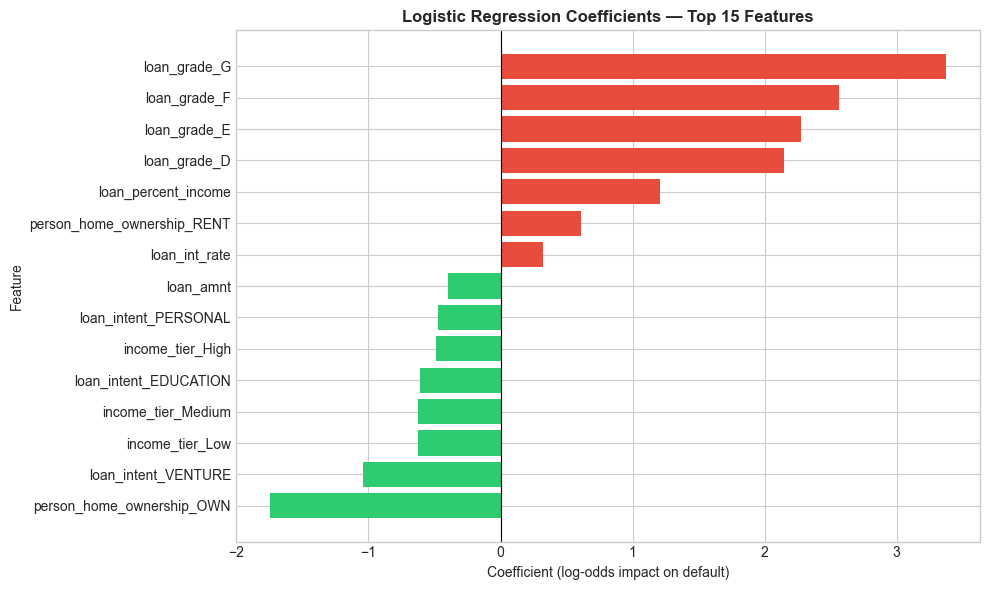

In [ ]:
coef_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "coefficient": log_reg.coef_[0]
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False)

print("Top 15 drivers of default risk (by |coefficient|):")
display(coef_df.head(15).round(4))

# Visualization — top 15 features
top_n = 15
plot_df = coef_df.head(top_n).sort_values("coefficient")

plt.figure(figsize=(10, 6))
colors = ["#e74c3c" if c > 0 else "#2ecc71" for c in plot_df["coefficient"]]
plt.barh(plot_df["feature"], plot_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Coefficients — Top 15 Features", fontweight="bold")
plt.xlabel("Coefficient (log-odds impact on default)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Coefficient Interpretation (Finance Lens)

- **Positive coefficient** → increases log-odds of **default** (higher credit risk).  
- **Negative coefficient** → decreases log-odds of default (lower credit risk).  

Because features are **standardized**, coefficients are comparable in magnitude. Key business signals typically include:

- `loan_percent_income` / `high_payment_burden` — affordability stress  
- `loan_int_rate` / `loan_grade` — risk-based pricing  
- `prior_default_flag` — behavioral credit history  
- `person_income` / `income_to_loan_ratio` — repayment capacity


## 5. Error Analysis — False Positives & False Negatives


In [ ]:
tn, fp, fn, tp = cm.ravel()

error_df = pd.DataFrame({
    "Error Type": ["True Negative (TN)", "False Positive (FP)", "False Negative (FN)", "True Positive (TP)"],
    "Count": [tn, fp, fn, tp],
    "Definition": [
        "Correctly approved good borrower",
        "Good borrower rejected (Type I)",
        "Bad borrower approved (Type II)",
        "Correctly flagged default risk"
    ]
})
display(error_df)

print(f"False Positive Rate: {fp / (fp + tn):.2%} of good borrowers misclassified as default")
print(f"False Negative Rate: {fn / (fn + tp):.2%} of defaulters misclassified as safe")


,Error Type,Count,Definition
0,True Negative (TN),4169,Correctly approved good borrower
1,False Positive (FP),897,Good borrower rejected (Type I)
2,False Negative (FN),310,Bad borrower approved (Type II)
3,True Positive (TP),1108,Correctly flagged default risk


False Positive Rate: 17.71% of good borrowers misclassified as default
False Negative Rate: 21.86% of defaulters misclassified as safe


### Business Interpretation of Errors

| Error | Credit Risk Meaning | Business Impact |
|-------|---------------------|-----------------|
| **False Positive (FP)** | Safe borrower predicted as defaulter | Lost revenue, customer friction, unfair decline |
| **False Negative (FN)** | Defaulter predicted as safe | **Credit loss**, capital impairment, regulatory concern |

In unsecured consumer lending, **false negatives are typically more costly** than false positives. The optimal decision threshold should reflect:

- **Cost of FN** ≈ Loss Given Default × Exposure  
- **Cost of FP** ≈ Foregone interest margin + acquisition cost  

The `class_weight='balanced'` setting improves **recall on defaults**, aligning the model with prudent risk management.


---
# Part 3 — Operationalization and Business Impact


## 1. Credit Risk Strategy and Segmentation


Risk Segmentation Summary (Test Set):


,borrowers,avg_pd,actual_default_rate,avg_loan_amount
risk_segment,,,,
High Risk,2667,0.6874,0.4518,"10,382.0022"
Low Risk,2007,0.0813,0.0329,"8,825.2491"
Medium Risk,1810,0.2376,0.0812,"8,550.2762"


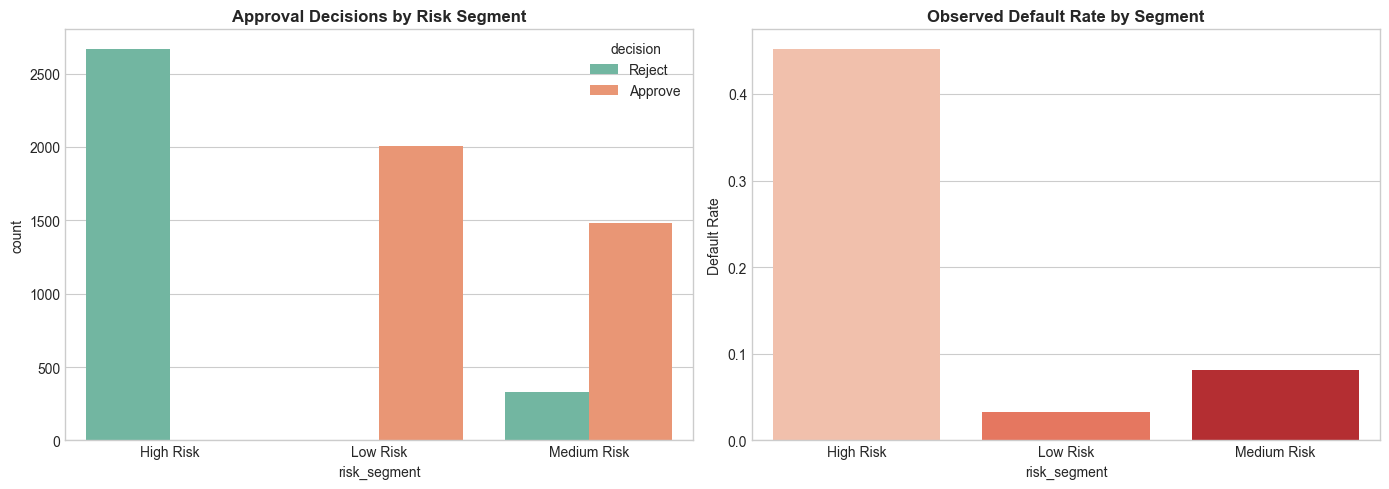

In [ ]:
# Risk segmentation on test portfolio using predicted PD
test_results = pd.DataFrame({
    "actual_default": y_test.values,
    "pd": y_prob,
    "loan_amnt": df.loc[y_test.index, "loan_amnt"].values,
    "person_income": df.loc[y_test.index, "person_income"].values,
    "loan_percent_income": df.loc[y_test.index, "loan_percent_income"].values,
})

# Risk buckets
def assign_risk_segment(pd_score):
    if pd_score < 0.15:
        return "Low Risk"
    elif pd_score < 0.35:
        return "Medium Risk"
    return "High Risk"

test_results["risk_segment"] = test_results["pd"].apply(assign_risk_segment)

# Approval policy: approve Low + Medium below 0.30, reject High
APPROVAL_THRESHOLD = 0.30
test_results["decision"] = np.where(test_results["pd"] < APPROVAL_THRESHOLD, "Approve", "Reject")

segment_summary = test_results.groupby("risk_segment").agg(
    borrowers=("pd", "count"),
    avg_pd=("pd", "mean"),
    actual_default_rate=("actual_default", "mean"),
    avg_loan_amount=("loan_amnt", "mean")
).round(4)

print("Risk Segmentation Summary (Test Set):")
display(segment_summary)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=test_results, x="risk_segment", hue="decision", ax=axes[0], palette="Set2")
axes[0].set_title("Approval Decisions by Risk Segment", fontweight="bold")

sns.barplot(
    data=test_results.groupby("risk_segment")["actual_default"].mean().reset_index(),
    x="risk_segment", y="actual_default", ax=axes[1], palette="Reds"
)
axes[1].set_title("Observed Default Rate by Segment", fontweight="bold")
axes[1].set_ylabel("Default Rate")

plt.tight_layout()
plt.show()


### Approval / Rejection Logic

| Segment | PD Range | Policy |
|---------|----------|--------|
| **Low Risk** | PD < 15% | Approve — standard pricing |
| **Medium Risk** | 15% ≤ PD < 35% | Approve with monitoring / higher rate |
| **High Risk** | PD ≥ 35% | Reject or require collateral / co-signer |

**Operational rule implemented:** Approve if PD < 30%; otherwise reject.


## 2. Expected Loss Analysis


**Expected Loss (EL)** framework:

$$EL = PD \times LGD \times EAD$$

| Parameter | Definition | Assumption in this analysis |
|-----------|------------|----------------------------|
| **PD** | Probability of Default | Model predicted probability |
| **LGD** | Loss Given Default | **45%** (unsecured personal loan industry benchmark) |
| **EAD** | Exposure at Default | **Loan amount** (`loan_amnt`) |


Expected Loss Analysis — Test Portfolio
Total Exposure (EAD):     $60,877,075
Total Expected Loss:      $11,107,606
Portfolio EL Rate:        18.25%
Assumed LGD:              45%

Expected Loss by Risk Segment:


,expected_loss
risk_segment,
High Risk,"8,814,505.5100"
Medium Risk,"1,659,118.3200"
Low Risk,"633,982.5700"


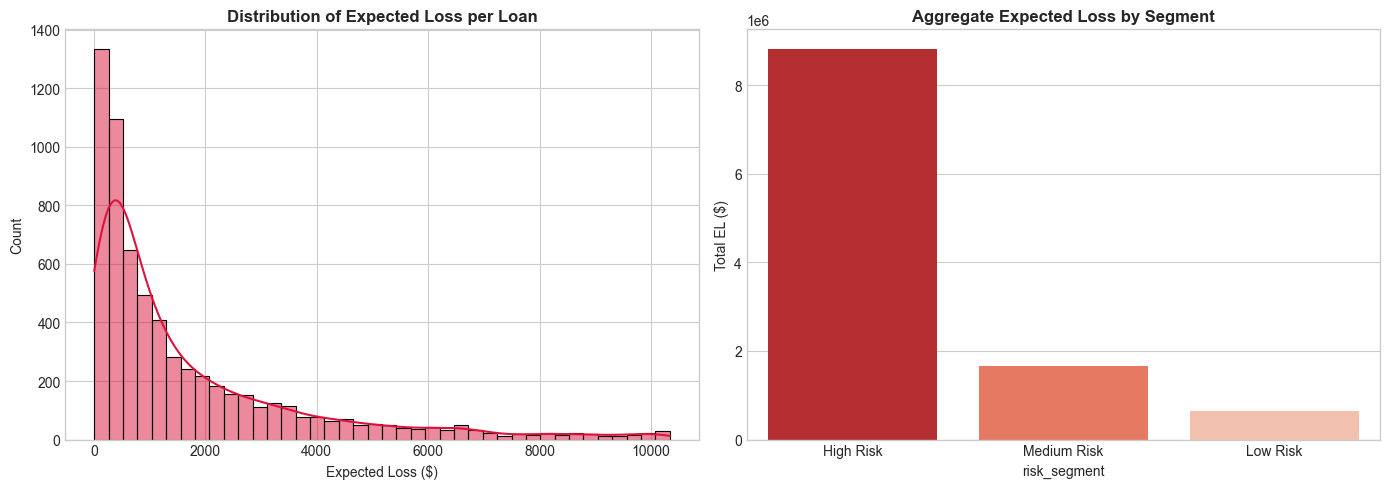


EL on approved book:  $1,859,452
EL on rejected book:  $9,248,154 (risk avoided by policy)


In [ ]:
LGD = 0.45  # 45% — conservative assumption for unsecured consumer credit
EAD = test_results["loan_amnt"]

test_results["lgd"] = LGD
test_results["ead"] = EAD
test_results["el"] = test_results["pd"] * test_results["lgd"] * test_results["ead"]

# Portfolio-level EL
total_el = test_results["el"].sum()
total_exposure = test_results["ead"].sum()
el_rate = total_el / total_exposure

print("Expected Loss Analysis — Test Portfolio")
print("=" * 50)
print(f"Total Exposure (EAD):     ${total_exposure:,.0f}")
print(f"Total Expected Loss:      ${total_el:,.0f}")
print(f"Portfolio EL Rate:        {el_rate:.2%}")
print(f"Assumed LGD:              {LGD:.0%}")

el_by_segment = test_results.groupby("risk_segment")["el"].sum().sort_values(ascending=False)
print("\nExpected Loss by Risk Segment:")
display(el_by_segment.to_frame("expected_loss").round(2))

# EL visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(test_results["el"], bins=40, kde=True, ax=axes[0], color="crimson")
axes[0].set_title("Distribution of Expected Loss per Loan", fontweight="bold")
axes[0].set_xlabel("Expected Loss ($)")

sns.barplot(x=el_by_segment.index, y=el_by_segment.values, ax=axes[1], palette="Reds_r")
axes[1].set_title("Aggregate Expected Loss by Segment", fontweight="bold")
axes[1].set_ylabel("Total EL ($)")

plt.tight_layout()
plt.show()

# If we only approve PD < threshold — avoided EL
approved = test_results[test_results["decision"] == "Approve"]
rejected = test_results[test_results["decision"] == "Reject"]
print(f"\nEL on approved book:  ${approved['el'].sum():,.0f}")
print(f"EL on rejected book:  ${rejected['el'].sum():,.0f} (risk avoided by policy)")


## 3. Final Conclusion


### Key Findings

1. **Portfolio profile:** The dataset exhibits class imbalance (~22% default rate), typical of consumer credit portfolios where defaults are the minority but economically dominant event.

2. **Risk drivers:** Payment burden (`loan_percent_income`), interest rate / loan grade, prior default history, and credit history length are among the strongest discriminators between safe and risky borrowers.

3. **Data quality:** Missing interest rates and employment lengths were imputed; extreme outliers in age and income were winsorized to improve model stability.

### Model Performance

- Logistic Regression provides a **transparent, regulator-friendly** scoring function with competitive ROC-AUC on the hold-out test set.
- Balanced class weights improve **default detection (recall)** at the cost of some false positives — a prudent trade-off for unsecured lending.

### Business Impact

- **Risk segmentation** (Low / Medium / High) enables differentiated pricing, limits, and approval policies.
- **Expected Loss** quantification supports capital allocation, provisioning, and portfolio planning.
- A **PD threshold of 30%** reduces exposure to high-EL segments while preserving volume in lower-risk tiers.

### Limitations

- Cross-sectional data; no temporal validation or economic cycle stress testing.
- `loan_grade` may embed lender decisions — potential endogeneity for application-stage models.
- LGD and EAD assumptions are static; real losses vary by collateral, recovery, and collections.

### Future Improvements

- Calibrate PD scores (Platt scaling / isotonic regression) for regulatory capital models.
- Add **reject inference** and macroeconomic features (unemployment, rate environment).
- Compare with **XGBoost** for accuracy while using SHAP for explainability.
- Implement **KS statistic**, **Gini**, and **Population Stability Index (PSI)** for model monitoring.
- Back-test approval policy on out-of-time samples and optimize threshold via cost-sensitive learning.

---

*End of Credit Risk Scoring Workflow*
